# Project Name - Airline Flight Analytics

### Import Libraries

In [35]:
%pip install sqlalchemy pymysql cryptography openpyxl

Note: you may need to restart the kernel to use updated packages.


In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()
import os

from sqlalchemy import create_engine
from sqlalchemy.engine import URL

OUTPUT_DIR = "airline_analytics_charts"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


## CONFIGURATION

In [37]:
username = "root"
password = "123456"

url = URL.create(
    drivername="mysql+pymysql",
    username=username,
    password=password,
    host="127.0.0.1",
    port=3306,
    database="airline_analytics"
)

db_engine = create_engine(url)
print("Engine Created Successfully")

Engine Created Successfully


In [38]:
try:
    with db_engine.connect() as conn:
        print("Database Connected Successfully")
except Exception as e:
    print("Connection Error:", e)

Database Connected Successfully


In [39]:
df = pd.read_sql("SELECT * FROM airline_flight_analytics", db_engine)
print(df.head())
print("Dataset Shape:", df.shape)

  Flight_ID Flight_Date    Airline Flight_Number Origin_Airport  \
0   FL00001  2025-04-17  Air India        AI5834   Mumbai (BOM)   
1   FL00002  2025-06-19     IndiGo         6E289     Pune (PNQ)   
2   FL00003  2025-04-02     IndiGo        6E9770   Jaipur (JAI)   
3   FL00004  2025-08-03  Air India        AI6963      Goa (GOI)   
4   FL00005  2025-06-12   SpiceJet        SG5992      Goa (GOI)   

  Destination_Airport Origin_City Destination_City  Distance_KM  \
0          Pune (PNQ)      Mumbai             Pune          816   
1       Chennai (MAA)        Pune          Chennai          912   
2     Bengaluru (BLR)      Jaipur        Bengaluru         1125   
3       Kolkata (CCU)         Goa          Kolkata          687   
4        Jaipur (JAI)         Goa           Jaipur          550   

  Scheduled_Departure  ... Baggage_Revenue Ancillary_Revenue Total_Revenue  \
0     0 days 12:00:00  ...           50809             56024        886550   
1     0 days 20:30:00  ...            

## 1. LOAD AND PREPARE DATA

In [40]:
# Convert flight date
df.columns = df.columns.str.strip()

# Standardize column names from the SQL table so all analysis modules use one schema.
column_aliases = {
    "Total_Seats": "Capacity",
    "Load_Factor_Pct": "Load_Factor",
    "Departure_Delay_Min": "Departure_Delay_Minutes",
    "Arrival_Delay_Min": "Arrival_Delay_Minutes",
}
df = df.rename(columns={old: new for old, new in column_aliases.items() if old in df.columns and new not in df.columns})

# If load factor is absent but passenger and seat counts are available, calculate it.
if "Load_Factor" not in df.columns and {"Passengers", "Capacity"}.issubset(df.columns):
    df["Load_Factor"] = np.where(df["Capacity"] > 0, df["Passengers"] / df["Capacity"] * 100, np.nan)
df["Flight_Date"] = pd.to_datetime(df["Flight_Date"], errors="coerce")

# Convert numeric columns safely
numeric_columns = [
    "Distance_KM", "Departure_Delay_Minutes", "Arrival_Delay_Minutes",
    "Passengers", "Capacity", "Load_Factor", "Ticket_Revenue",
    "Baggage_Revenue", "Ancillary_Revenue", "Total_Revenue",
    "Operating_Cost", "Profit"
]
for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Derive date fields when they are not already present
df["Year"] = df["Flight_Date"].dt.year
df["Month"] = df["Flight_Date"].dt.month
df["Month_Name"] = df["Flight_Date"].dt.month_name()
df["Day_Name"] = df["Flight_Date"].dt.day_name()

print("Flight date and numeric columns prepared successfully.")

Flight date and numeric columns prepared successfully.


In [41]:
# Remove duplicate flight records
df = df.drop_duplicates()
print("Duplicate records removed.")

Duplicate records removed.


In [42]:
# Dataset Shape
print(df.shape)

(200, 39)


In [43]:
# First 5 Records
print(df.head(5))

  Flight_ID Flight_Date    Airline Flight_Number Origin_Airport  \
0   FL00001  2025-04-17  Air India        AI5834   Mumbai (BOM)   
1   FL00002  2025-06-19     IndiGo         6E289     Pune (PNQ)   
2   FL00003  2025-04-02     IndiGo        6E9770   Jaipur (JAI)   
3   FL00004  2025-08-03  Air India        AI6963      Goa (GOI)   
4   FL00005  2025-06-12   SpiceJet        SG5992      Goa (GOI)   

  Destination_Airport Origin_City Destination_City  Distance_KM  \
0          Pune (PNQ)      Mumbai             Pune          816   
1       Chennai (MAA)        Pune          Chennai          912   
2     Bengaluru (BLR)      Jaipur        Bengaluru         1125   
3       Kolkata (CCU)         Goa          Kolkata          687   
4        Jaipur (JAI)         Goa           Jaipur          550   

  Scheduled_Departure  ...  Profit Origin_Region Destination_Region  \
0     0 days 12:00:00  ...  208123          West               West   
1     0 days 20:30:00  ...       0          West    

In [44]:
# Column Names
print(df.columns.tolist())

['Flight_ID', 'Flight_Date', 'Airline', 'Flight_Number', 'Origin_Airport', 'Destination_Airport', 'Origin_City', 'Destination_City', 'Distance_KM', 'Scheduled_Departure', 'Scheduled_Arrival', 'Actual_Departure', 'Actual_Arrival', 'Flight_Duration_Min', 'Departure_Delay_Minutes', 'Arrival_Delay_Minutes', 'Flight_Status', 'Cancelled', 'Cancellation_Reason', 'Capacity', 'Passengers', 'Load_Factor', 'Cabin_Class', 'Average_Ticket_Price', 'Ticket_Revenue', 'Baggage_Revenue', 'Ancillary_Revenue', 'Total_Revenue', 'Operating_Cost', 'Profit', 'Origin_Region', 'Destination_Region', 'Flight_Type', 'Booking_Channel', 'Demand_Level', 'Year', 'Month', 'Month_Name', 'Day_Name']


In [45]:
# Missing Values
print(df.isnull().sum())

Flight_ID                   0
Flight_Date                 0
Airline                     0
Flight_Number               0
Origin_Airport              0
Destination_Airport         0
Origin_City                 0
Destination_City            0
Distance_KM                 0
Scheduled_Departure         0
Scheduled_Arrival           0
Actual_Departure           14
Actual_Arrival             14
Flight_Duration_Min         0
Departure_Delay_Minutes     0
Arrival_Delay_Minutes       0
Flight_Status               0
Cancelled                   0
Cancellation_Reason         0
Capacity                    0
Passengers                  0
Load_Factor                 0
Cabin_Class                 0
Average_Ticket_Price        0
Ticket_Revenue              0
Baggage_Revenue             0
Ancillary_Revenue           0
Total_Revenue               0
Operating_Cost              0
Profit                      0
Origin_Region               0
Destination_Region          0
Flight_Type                 0
Booking_Ch

In [46]:
# Data Types
print(df.dtypes)

Flight_ID                              str
Flight_Date                  datetime64[s]
Airline                                str
Flight_Number                          str
Origin_Airport                         str
Destination_Airport                    str
Origin_City                            str
Destination_City                       str
Distance_KM                          int64
Scheduled_Departure        timedelta64[us]
Scheduled_Arrival          timedelta64[us]
Actual_Departure           timedelta64[us]
Actual_Arrival             timedelta64[us]
Flight_Duration_Min                  int64
Departure_Delay_Minutes              int64
Arrival_Delay_Minutes                int64
Flight_Status                          str
Cancelled                              str
Cancellation_Reason                    str
Capacity                             int64
Passengers                           int64
Load_Factor                        float64
Cabin_Class                            str
Average_Tic

In [47]:
# GENERAL KPI ANALYSIS
total_flights = df["Flight_ID"].nunique()
total_airlines = df["Airline"].nunique()
total_routes = df[["Origin_Airport", "Destination_Airport"]].drop_duplicates().shape[0]
total_passengers = df["Passengers"].sum()
total_capacity = df["Capacity"].sum()
average_load_factor = df["Load_Factor"].mean()
total_revenue = df["Total_Revenue"].sum()
total_profit = df["Profit"].sum()
total_operating_cost = df["Operating_Cost"].sum()
average_departure_delay = df["Departure_Delay_Minutes"].mean()
average_arrival_delay = df["Arrival_Delay_Minutes"].mean()

print("\n" + "=" * 35)
print("AIRLINE FLIGHT ANALYTICS KPIs")
print("=" * 35)
print(f"Total Flights          : {total_flights:,}")
print(f"Total Airlines         : {total_airlines:,}")
print(f"Total Routes           : {total_routes:,}")
print(f"Total Passengers       : {total_passengers:,.0f}")
print(f"Total Capacity         : {total_capacity:,.0f}")
print(f"Average Load Factor    : {average_load_factor:.2f}%")
print(f"Total Revenue          : ₹{total_revenue:,.2f}")
print(f"Total Operating Cost   : ₹{total_operating_cost:,.2f}")
print(f"Total Profit           : ₹{total_profit:,.2f}")
print(f"Average Departure Delay: {average_departure_delay:.2f} minutes")
print(f"Average Arrival Delay  : {average_arrival_delay:.2f} minutes")


AIRLINE FLIGHT ANALYTICS KPIs
Total Flights          : 200
Total Airlines         : 6
Total Routes           : 79
Total Passengers       : 26,807
Total Capacity         : 37,106
Average Load Factor    : 72.41%
Total Revenue          : ₹208,854,353.00
Total Operating Cost   : ₹151,958,969.00
Total Profit           : ₹56,895,384.00
Average Departure Delay: 18.30 minutes
Average Arrival Delay  : 22.91 minutes


# MODULE 1 — FLIGHT PERFORMANCE
**Purpose:** Understand flights, status, distance and duration.

### 1.1 Airline-wise Flight Performance

In [48]:
flight_performance = (
    df.groupby("Airline")
      .agg(
          Flights=("Flight_ID", "nunique"),
          Average_Distance_KM=("Distance_KM", "mean"),
          Average_Duration_Min=("Flight_Duration_Min", "mean")
      )
      .reset_index()
)
display(flight_performance)

,Airline,Flights,Average_Distance_KM,Average_Duration_Min
0,Air India,33,1449.060606,198.090909
1,Air India Express,28,1476.535714,200.428571
2,Akasa Air,24,1313.708333,179.666667
3,IndiGo,66,1388.772727,195.166667
4,SpiceJet,26,1238.730769,173.192308
5,Vistara,23,1476.000000,203.217391


### 1.2 Flight Status Summary

In [49]:
status_analysis = df["Flight_Status"].value_counts().reset_index()
status_analysis.columns = ["Flight_Status", "Flights"]
display(status_analysis)

,Flight_Status,Flights
0,Delayed <30 min,86
1,Delayed 30-120 min,74
2,On Time,26
3,Cancelled,14


### 1.3 Flight Status Bar Chart

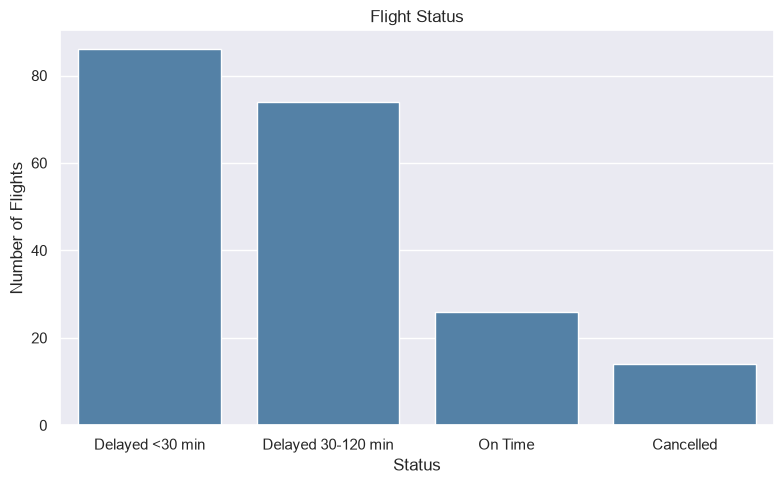

In [50]:
plt.figure(figsize=(8, 5))
sns.barplot(data=status_analysis, x="Flight_Status", y="Flights", color="steelblue")
plt.title("Flight Status")
plt.xlabel("Status")
plt.ylabel("Number of Flights")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "01_flight_status.png"), dpi=300)
plt.show()

# MODULE 2 — DELAY ANALYSIS
**Purpose:** Analyze departure delays, arrival delays and delay rate.

### 2.1 Calculate Airline-wise Delay Metrics

In [51]:
delay_analysis = (
    df.groupby("Airline")
      .agg(
          Flights=("Flight_ID", "nunique"),
          Average_Departure_Delay=("Departure_Delay_Minutes", "mean"),
          Average_Arrival_Delay=("Arrival_Delay_Minutes", "mean")
      )
      .reset_index()
)

df["Delayed"] = np.where(
    (df["Departure_Delay_Minutes"] > 0) | (df["Arrival_Delay_Minutes"] > 0),
    "Yes", "No"
)
delay_rate = (
    df.groupby("Airline")["Delayed"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .reset_index(name="Delay_Rate_Pct")
)
delay_analysis = delay_analysis.merge(delay_rate, on="Airline")
display(delay_analysis)

,Airline,Flights,Average_Departure_Delay,Average_Arrival_Delay,Delay_Rate_Pct
0,Air India,33,19.727273,23.181818,84.848485
1,Air India Express,28,20.428571,24.714286,89.285714
2,Akasa Air,24,15.625000,19.291667,79.166667
3,IndiGo,66,18.530303,25.621212,84.848485
4,SpiceJet,26,20.923077,23.230769,76.923077
5,Vistara,23,12.782609,16.000000,82.608696


### 2.2 Average Arrival Delay Chart

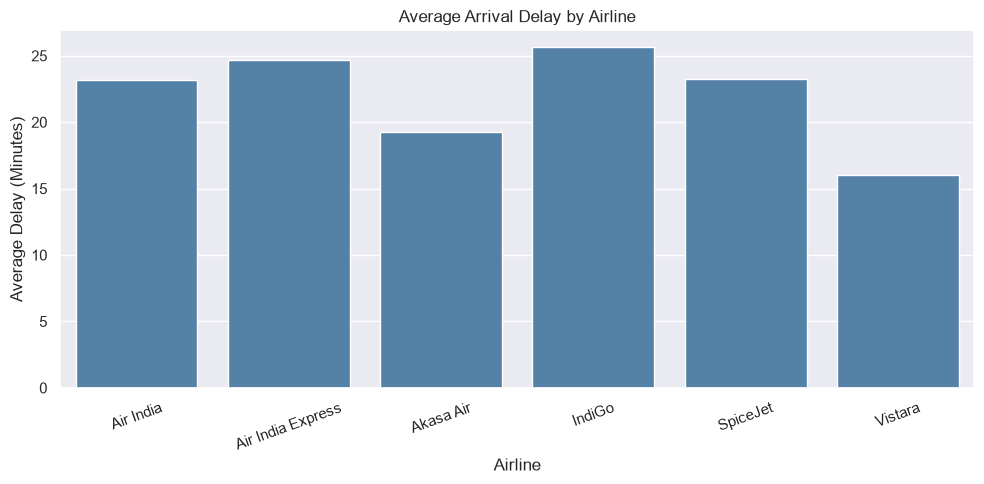

In [52]:
plt.figure(figsize=(10, 5))
sns.barplot(data=delay_analysis, x="Airline", y="Average_Arrival_Delay", color="steelblue")
plt.title("Average Arrival Delay by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "02_average_arrival_delay.png"), dpi=300)
plt.show()

# MODULE 3 — CANCELLATION ANALYSIS
**Purpose:** Measure cancellation rate and identify major cancellation reasons.

### 3.1 Cancellation Rate

In [53]:
# Derive a consistent cancellation flag from the flight status.
df["Cancelled_Flag"] = df["Flight_Status"].astype(str).str.lower().str.contains("cancel", na=False)
cancellation_rate = (
    df["Cancelled_Flag"].value_counts(normalize=True).mul(100).reset_index()
)
cancellation_rate.columns = ["Cancelled", "Percentage"]
display(cancellation_rate)

,Cancelled,Percentage
0,False,93.0
1,True,7.0


### 3.2 Cancellation Reasons

In [54]:
if "Cancellation_Reason" in df.columns:
    reasons = (
        df.loc[df["Cancelled_Flag"], "Cancellation_Reason"]
          .value_counts()
          .reset_index()
    )
    reasons.columns = ["Cancellation_Reason", "Flights"]
else:
    reasons = pd.DataFrame(columns=["Cancellation_Reason", "Flights"])
display(reasons)

,Cancellation_Reason,Flights
0,Operational Issue,6
1,Technical Issue,3
2,Weather,3
3,Crew Shortage,2


### 3.3 Cancellation Reasons Chart

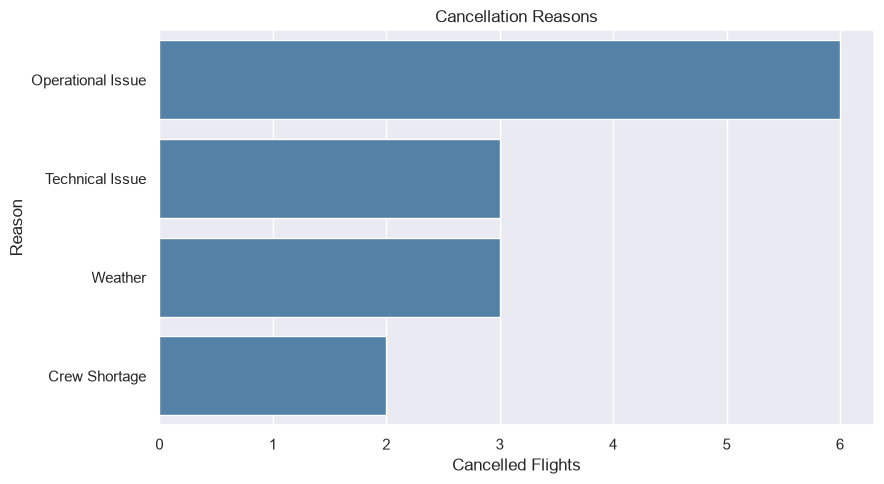

In [55]:
if not reasons.empty:
    plt.figure(figsize=(9, 5))
    sns.barplot(data=reasons, x="Flights", y="Cancellation_Reason", color="steelblue")
    plt.title("Cancellation Reasons")
    plt.xlabel("Cancelled Flights")
    plt.ylabel("Reason")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "03_cancellation_reasons.png"), dpi=300)
    plt.show()
else:
    print("Cancellation reason data is not available.")

# MODULE 4 — PASSENGER ANALYTICS
**Purpose:** Analyze passengers, seats, load factor and cabin class.

### 4.1 Airline-wise Passenger Analysis

In [56]:
passenger_analysis = (
    df.groupby("Airline")
      .agg(
          Passengers=("Passengers", "sum"),
          Seats=("Capacity", "sum"),
          Average_Load_Factor=("Load_Factor", "mean")
      )
      .reset_index()
)
display(passenger_analysis)

,Airline,Passengers,Seats,Average_Load_Factor
0,Air India,4519,6080,74.243030
1,Air India Express,4198,5326,79.062143
2,Akasa Air,2746,4334,63.263333
3,IndiGo,8865,12515,71.081818
4,SpiceJet,3273,4526,72.500385
5,Vistara,3206,4325,74.959130


### 4.2 Cabin Class Analysis

In [57]:
if "Cabin_Class" in df.columns:
    cabin_analysis = (
        df.groupby("Cabin_Class")
          .agg(
              Passengers=("Passengers", "sum"),
              Average_Load_Factor=("Load_Factor", "mean")
          )
          .reset_index()
    )
    display(cabin_analysis)
else:
    cabin_analysis = pd.DataFrame()
    print("Cabin_Class column is not available in this dataset.")

,Cabin_Class,Passengers,Average_Load_Factor
0,Business,3042,70.511818
1,Economy,18881,72.220280
2,Mixed,4884,74.394000


### 4.3 Passengers by Cabin Class Chart

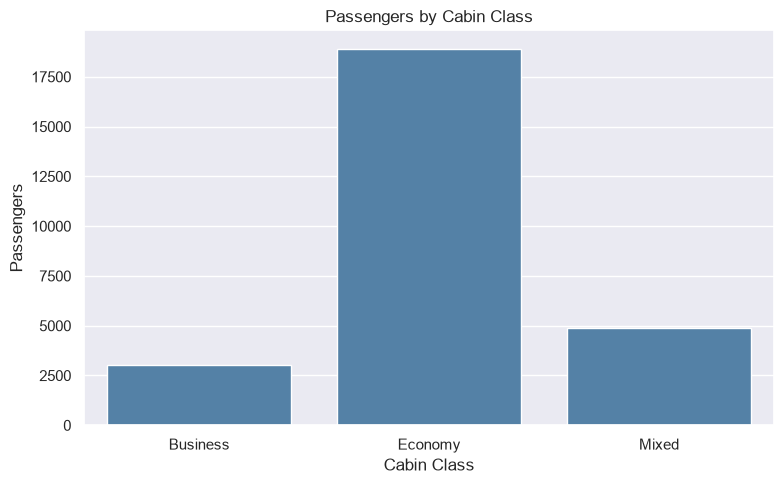

In [58]:
if not cabin_analysis.empty:
    plt.figure(figsize=(8, 5))
    sns.barplot(data=cabin_analysis, x="Cabin_Class", y="Passengers", color="steelblue")
    plt.title("Passengers by Cabin Class")
    plt.xlabel("Cabin Class")
    plt.ylabel("Passengers")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "04_passengers_by_cabin_class.png"), dpi=300)
    plt.show()
else:
    print("Cabin class chart skipped because cabin data is unavailable.")

# MODULE 5 — ROUTE ANALYTICS
**Purpose:** Find important origin-destination routes and compare distance and passengers.

### 5.1 Route-wise Analysis

In [59]:
route_analysis = (
    df.groupby(["Origin_City", "Destination_City"])
      .agg(
          Flights=("Flight_ID", "nunique"),
          Distance_KM=("Distance_KM", "mean"),
          Passengers=("Passengers", "sum"),
          Revenue=("Total_Revenue", "sum")
      )
      .reset_index()
)
top_routes = route_analysis.sort_values("Passengers", ascending=False).head(10)
display(top_routes)

,Origin_City,Destination_City,Flights,Distance_KM,Passengers,Revenue
41,Hyderabad,Jaipur,7,1218.857143,1081,9411888
25,Delhi,Goa,7,1626.142857,860,7532900
55,Kolkata,Delhi,5,1378.000000,760,5469089
26,Delhi,Hyderabad,5,1098.200000,712,6680396
21,Chennai,Mumbai,5,1445.200000,672,5971925
19,Chennai,Jaipur,5,1462.800000,670,4885792
5,Ahmedabad,Jaipur,5,1754.800000,662,4481578
13,Bengaluru,Jaipur,4,1498.500000,653,6023217
69,Mumbai,Pune,5,1389.400000,648,5424083
27,Delhi,Jaipur,4,1116.750000,624,4880200


### 5.2 Top 10 Routes by Passengers Chart

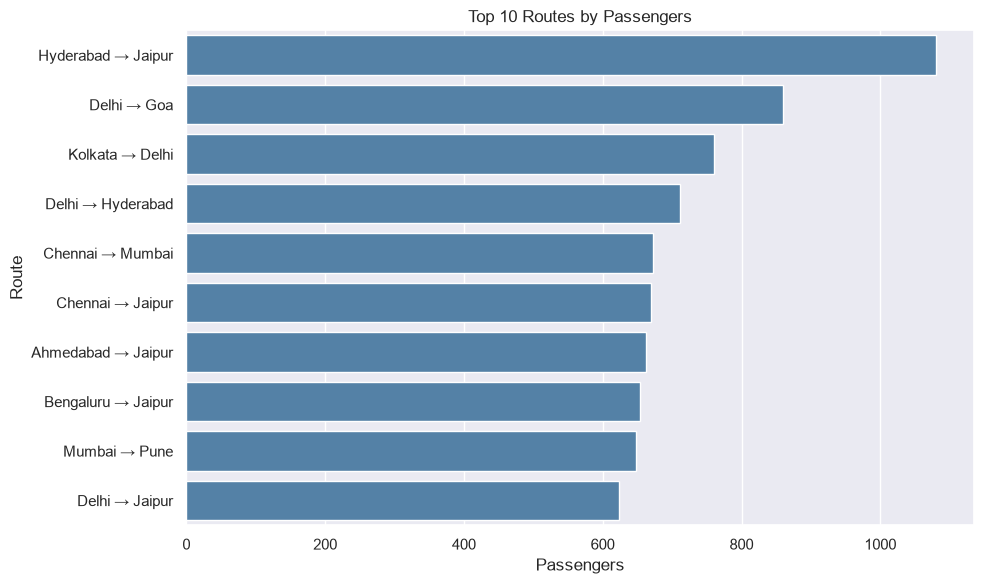

In [60]:
if not top_routes.empty:
    plt.figure(figsize=(10, 6))
    route_labels = top_routes["Origin_City"].astype(str) + " → " + top_routes["Destination_City"].astype(str)
    sns.barplot(x=top_routes["Passengers"], y=route_labels, color="steelblue")
    plt.title("Top 10 Routes by Passengers")
    plt.xlabel("Passengers")
    plt.ylabel("Route")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "05_top_routes_by_passengers.png"), dpi=300)
    plt.show()

# MODULE 6 — AIRPORT PERFORMANCE
**Purpose:** Compare airport activity, delays and cancellations.

### 6.1 Origin Airport Performance

In [61]:
origin_airport = (
    df.groupby("Origin_Airport")
      .agg(
          Flights=("Flight_ID", "nunique"),
          Average_Departure_Delay=("Departure_Delay_Minutes", "mean"),
          Cancelled_Flights=("Cancelled_Flag", "sum")
      )
      .reset_index()
      .sort_values("Flights", ascending=False)
)
display(origin_airport.head(10))

,Origin_Airport,Flights,Average_Departure_Delay,Cancelled_Flights
5,Hyderabad (HYD),29,22.931034,3
3,Delhi (DEL),25,15.040000,4
6,Jaipur (JAI),22,13.136364,1
0,Ahmedabad (AMD),22,24.454545,1
8,Mumbai (BOM),20,23.200000,0
1,Bengaluru (BLR),18,12.555556,2
9,Pune (PNQ),18,15.277778,2
2,Chennai (MAA),17,22.294118,0
4,Goa (GOI),17,17.000000,0
7,Kolkata (CCU),12,13.166667,1


### 6.2 Top 10 Origin Airports Chart

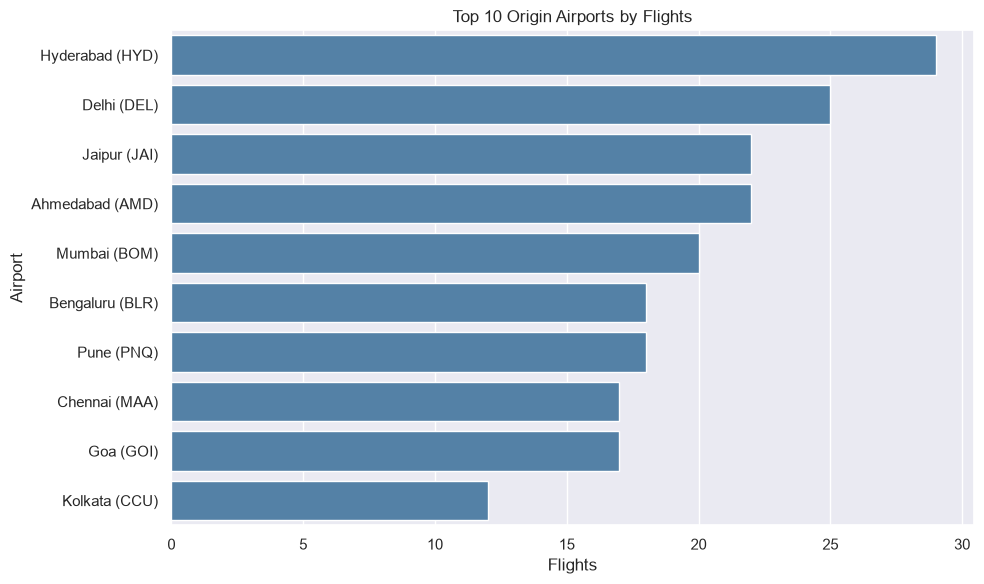

In [62]:
top_airports = origin_airport.head(10)
plt.figure(figsize=(10, 6))
sns.barplot(data=top_airports, x="Flights", y="Origin_Airport", color="steelblue")
plt.title("Top 10 Origin Airports by Flights")
plt.xlabel("Flights")
plt.ylabel("Airport")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "06_top_origin_airports.png"), dpi=300)
plt.show()

# MODULE 7 — AIRLINE PERFORMANCE
**Purpose:** Compare airlines using flights, delays, passengers, revenue and profit.

### 7.1 Airline Performance Metrics

In [63]:
airline_performance = (
    df.groupby("Airline")
      .agg(
          Flights=("Flight_ID", "nunique"),
          Passengers=("Passengers", "sum"),
          Average_Delay=("Arrival_Delay_Minutes", "mean"),
          Revenue=("Total_Revenue", "sum"),
          Cost=("Operating_Cost", "sum"),
          Profit=("Profit", "sum")
      )
      .reset_index()
)
airline_performance["Profit_Margin_Pct"] = (
    airline_performance["Profit"] /
    airline_performance["Revenue"].replace(0, np.nan) * 100
)
display(airline_performance.sort_values("Revenue", ascending=False))

,Airline,Flights,Passengers,Average_Delay,Revenue,Cost,Profit,Profit_Margin_Pct
3,IndiGo,66,8865,25.621212,69534665,50681843,18852822,27.112839
0,Air India,33,4519,23.181818,34913088,25485657,9427431,27.002570
1,Air India Express,28,4198,24.714286,32829002,23319602,9509400,28.966461
4,SpiceJet,26,3273,23.230769,26524259,19859592,6664667,25.126685
5,Vistara,23,3206,16.000000,23308017,17115114,6192903,26.569841
2,Akasa Air,24,2746,19.291667,21745322,15497161,6248161,28.733357


### 7.2 Airline-wise Profit Chart

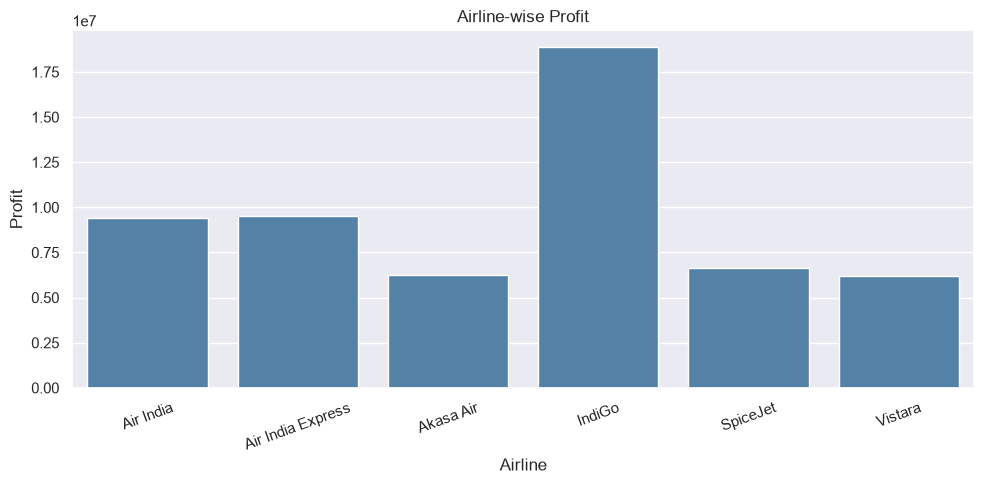

In [64]:
plt.figure(figsize=(10, 5))
sns.barplot(data=airline_performance, x="Airline", y="Profit", color="steelblue")
plt.title("Airline-wise Profit")
plt.xlabel("Airline")
plt.ylabel("Profit")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "07_airline_profit.png"), dpi=300)
plt.show()

# MODULE 8 — REVENUE DASHBOARD
**Purpose:** Analyze ticket, baggage and ancillary revenue along with cost and profit.

### 8.1 Revenue by Airline

In [65]:
revenue_analysis = (
    df.groupby("Airline")
      .agg(
          Ticket_Revenue=("Ticket_Revenue", "sum"),
          Baggage_Revenue=("Baggage_Revenue", "sum"),
          Ancillary_Revenue=("Ancillary_Revenue", "sum"),
          Total_Revenue=("Total_Revenue", "sum"),
          Operating_Cost=("Operating_Cost", "sum"),
          Profit=("Profit", "sum")
      )
      .reset_index()
)
display(revenue_analysis)

,Airline,Ticket_Revenue,Baggage_Revenue,Ancillary_Revenue,Total_Revenue,Operating_Cost,Profit
0,Air India,31080407,1817485,2015196,34913088,25485657,9427431
1,Air India Express,29579048,1481561,1768393,32829002,23319602,9509400
2,Akasa Air,19585642,960639,1199041,21745322,15497161,6248161
3,IndiGo,62875083,3012933,3646649,69534665,50681843,18852822
4,SpiceJet,23924151,1185153,1414955,26524259,19859592,6664667
5,Vistara,20709769,1098126,1500122,23308017,17115114,6192903


### 8.2 Revenue Sources by Airline — Bar Chart

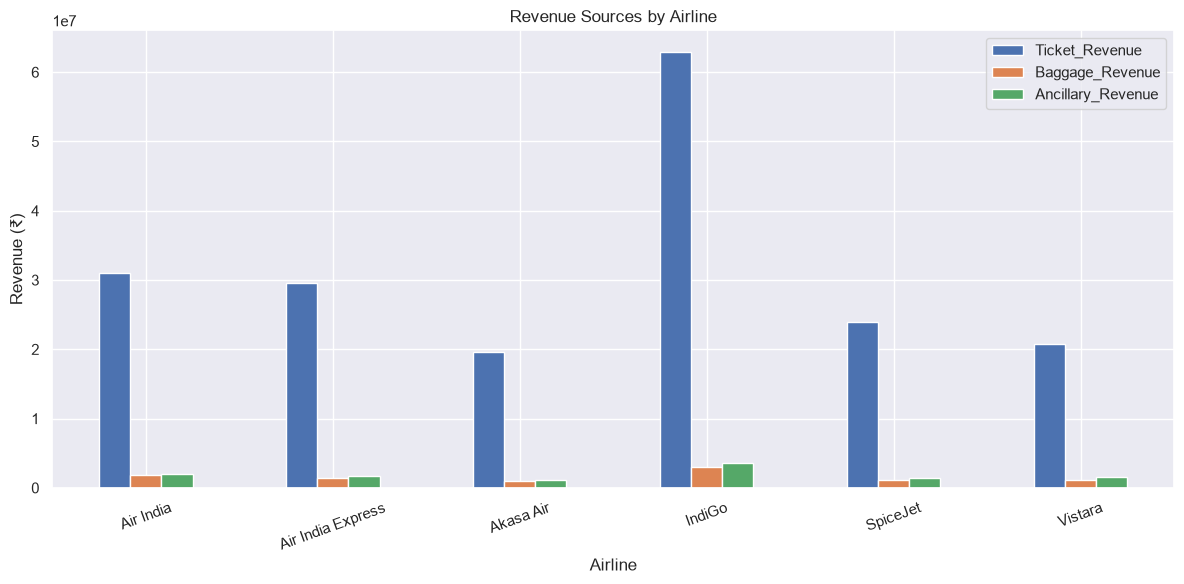

In [66]:
revenue_plot = revenue_analysis.set_index("Airline")[
    ["Ticket_Revenue", "Baggage_Revenue", "Ancillary_Revenue"]
]
revenue_plot.plot(kind="bar", figsize=(12, 6))
plt.title("Revenue Sources by Airline")
plt.xlabel("Airline")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "08_revenue_sources_by_airline.png"), dpi=300)
plt.show()

## 9. Close MySQL Connection

In [67]:
# Close the SQLAlchemy engine after completing all analysis
if "db_engine" in globals():
    db_engine.dispose()
    print("MySQL connection closed successfully.")

MySQL connection closed successfully.
